# Диффузионные методы переноса стиля — этап 1

Один последовательный запуск: данные → smoke test → 24 генерации → метрики → PDF. Основная логика находится в Python-модулях репозитория. LoRA и динамические коэффициенты здесь не реализованы.

Перед запуском сохраните код проекта в указанном GitHub-репозитории. Выберите **Среда выполнения → Сменить среду выполнения → T4 GPU**. Повторный запуск использует сохранённые данные и результаты в Drive.


## 1. Проверка окружения

Проверяем Python и наличие GPU. Модели на этом шаге не загружаются.


In [1]:
import os
from pathlib import Path
import subprocess
import sys

assert (3, 11) <= sys.version_info[:2] <= (3, 13), "Нужен Python 3.11–3.13 для закреплённого окружения"
subprocess.run(["nvidia-smi"], check=True)
print(sys.version)


3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]


## 2. Google Drive и расположение артефактов

Данные, кэш моделей, результаты и отчёт сохраняются между перезапусками. Окружение Python и checkout кода находятся на локальном диске Colab.


In [2]:
from google.colab import drive

drive.mount("/content/drive")
HOME_DIR = Path("/content/drive/MyDrive/diffusion_style_transfer")
HOME_DIR.mkdir(parents=True, exist_ok=True)
os.environ["DIFFUSION_STYLE_HOME"] = str(HOME_DIR)
os.environ["HF_HOME"] = str(HOME_DIR / ".cache/huggingface")
os.environ["MPLBACKEND"] = "Agg"
print("Артефакты:", HOME_DIR)


Mounted at /content/drive
Артефакты: /content/drive/MyDrive/diffusion_style_transfer


## 3. Загрузка или обновление репозитория

По умолчанию используется main. Для повторения конкретного состояния задайте GIT_REF полным commit SHA. Обновление допускается только для чистого checkout; пользовательские изменения автоматически не стираются.


In [11]:
REPO_URL = "https://github.com/Batyaoftheyear/diffusion-style.git"
GIT_REF = "main"
REPO = Path("/content/diffusion-style")


def git_command(*arguments, cwd=None):
    result = subprocess.run(
        ["git", *arguments], cwd=cwd, text=True,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        env={**os.environ, "GIT_TERMINAL_PROMPT": "0"},
    )
    if result.returncode:
        raise RuntimeError(
            f"Git завершился с кодом {result.returncode}: git {' '.join(arguments)}\n"
            f"{result.stdout.strip()}"
        )
    return result.stdout.strip()


remote_refs = git_command("ls-remote", REPO_URL)
if not remote_refs:
    raise RuntimeError(
        "GitHub-репозиторий пустой: удалённых веток и коммитов ещё нет. "
        "Сначала опубликуйте подготовленные файлы проекта в ветке main, "
        "затем повторите эту ячейку. Локальные файлы не появляются на GitHub автоматически."
    )

if not REPO.exists():
    print(git_command("clone", REPO_URL, str(REPO)))
assert (REPO / ".git").is_dir(), "Каталог должен быть отдельным git checkout"
remote = git_command("remote", "get-url", "origin", cwd=REPO)
assert remote.removesuffix(".git") == REPO_URL.removesuffix(".git"), "Другой origin"
status = git_command("status", "--porcelain", cwd=REPO)
assert not status, "В checkout есть изменения; сохраните их перед обновлением"
print(git_command("fetch", "origin", GIT_REF, cwd=REPO))
print(git_command("checkout", "--detach", "FETCH_HEAD", cwd=REPO))
print(git_command("rev-parse", "HEAD", cwd=REPO))


From https://github.com/Batyaoftheyear/diffusion-style
 * branch            main       -> FETCH_HEAD
   32efcf7..13220d2  main       -> origin/main
Previous HEAD position was 32efcf7 fix: use bundled Cyrillic fonts for portable PDF reports
HEAD is now at 13220d2 fix: retry transient dataset failures and resume cached catalogues
13220d2e82a6f9a83ec7effe0140cc3980b0cfc6


## 4. Установка закреплённых зависимостей

Используется отдельное окружение с pip, созданное автономным virtualenv: системный ensurepip не требуется. Проверяется контрольная сумма bootstrap-архива; частично созданное окружение автоматически дополняется pip. Предустановленные библиотеки Colab не заменяются. Вывод установки и ошибки видны в ячейке. Скачивание CUDA-библиотек и весов требует свободного места и времени.


In [5]:
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.bootstrap import ensure_environment, requirements_fingerprint, run_command

VENV = Path("/content/diffusion-style-env")
PYTHON = ensure_environment(VENV)
requirements = REPO / "requirements.txt"
requirements_sha = requirements_fingerprint(requirements)
marker = VENV / "requirements.sha256"
if not marker.exists() or marker.read_text().strip() != requirements_sha:
    run_command([PYTHON, "-m", "pip", "install", "-r", requirements], cwd=REPO)
    run_command([PYTHON, "-m", "pip", "check"], cwd=REPO)
    marker.write_text(requirements_sha)
else:
    run_command([PYTHON, "-m", "pip", "check"], cwd=REPO)
run_command([PYTHON, "-c", "import torch, diffusers, transformers; print(torch.__version__, diffusers.__version__, transformers.__version__); assert torch.cuda.is_available(); print(torch.cuda.get_device_name(0))"], cwd=REPO)


def run_script(name, *arguments):
    run_command([PYTHON, REPO / "scripts" / name, *arguments], cwd=REPO)


created virtual environment CPython3.13.16.final.0-64-x86_64 in 404ms
  creator CPython3Posix(dest=/content/diffusion-style-env, clear=False, no_vcs_ignore=False, venv_redirect=None, global=False)
  seeder FromAppData(download=False, pip=embed, via=copy, app_data_dir=/content/diffusion-style/.cache/bootstrap/app-data)
    added seed packages: pip==26.3
  activators BashActivator,CShellActivator,FishActivator,NushellActivator,PowerShellActivator,PythonActivator,XonshActivator
pip 26.3 from /content/diffusion-style-env/lib/python3.13/site-packages/pip (python 3.13)
Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu126
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.7/23.7 MB 153.7 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 897.7/897.7 kB 259.9 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 232.4 MB/s  0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 69.6 MB/s  0:00:08
     ━━━━━━━━━━━━━━━━━━━━━━━━

## 5. CPU-тесты до загрузки моделей

Тесты проверяют preprocessing, выборку, метрики, manifests, latents, resume и черновик PDF. GPU smoke test по умолчанию пропускается; он выполняется далее настоящим запуском пайплайна.


In [9]:
run_command([PYTHON, "-m", "unittest", "discover", "-s", "tests", "-v"], cwd=REPO)


test_real_partial_environment_is_repaired_and_reused (test_bootstrap.BootstrapTests.test_real_partial_environment_is_repaired_and_reused) ... ok
test_stderr_is_visible_and_included_in_error (test_bootstrap.BootstrapTests.test_stderr_is_visible_and_included_in_error) ... ok
test_system_environment_is_rejected (test_bootstrap.BootstrapTests.test_system_environment_is_rejected) ... ok
test_real_ip_adapter_and_controlnet (test_gpu_smoke.GpuSmokeTest.test_real_ip_adapter_and_controlnet) ... skipped 'requires prepared data and a real Colab CUDA GPU'
test_atomic_roundtrip_and_path_checks (test_stage1.ArtifactTests.test_atomic_roundtrip_and_path_checks) ... ok
test_latents_are_fixed_and_do_not_change_global_rng (test_stage1.ArtifactTests.test_latents_are_fixed_and_do_not_change_global_rng) ... ok
test_resume_rejects_damaged_files_and_wrong_identity (test_stage1.ArtifactTests.test_resume_rejects_damaged_files_and_wrong_identity) ... ok
test_baseline_defaults (test_stage1.ConfigTests.test_baseli

## 6. Подготовка и проверка данных

Загружаются 75 картин импрессионизма и 24 фото COCO, а не полные наборы изображений. Пять картин выделяются в референсы. Повторный запуск проверяет hashes и использует подготовленные файлы.


In [12]:
run_script("prepare_data.py")
run_script("prepare_data.py", "--check-only")


WikiArt metadata: 100 rows inspected
WikiArt metadata: 200 rows inspected
WikiArt metadata: 300 rows inspected
WikiArt metadata: 400 rows inspected
WikiArt metadata: 500 rows inspected
WikiArt metadata: 600 rows inspected
WikiArt metadata: 700 rows inspected
WikiArt metadata: 800 rows inspected
WikiArt metadata: 900 rows inspected
WikiArt metadata: 1000 rows inspected
WikiArt metadata: 1100 rows inspected
WikiArt metadata: 1200 rows inspected
WikiArt metadata: 1300 rows inspected
WikiArt metadata: 1400 rows inspected
WikiArt metadata: 1500 rows inspected
WikiArt: 1/75
WikiArt: 2/75
WikiArt: 3/75
WikiArt: 4/75
WikiArt: 5/75
WikiArt: 6/75
WikiArt: 7/75
WikiArt: 8/75
WikiArt: 9/75
WikiArt: 10/75
WikiArt: 11/75
WikiArt: 12/75
WikiArt: 13/75
WikiArt: 14/75
WikiArt: 15/75
WikiArt: 16/75
WikiArt: 17/75
WikiArt: 18/75
WikiArt: 19/75
WikiArt: 20/75
WikiArt: 21/75
WikiArt: 22/75
WikiArt: 23/75
WikiArt: 24/75
WikiArt: 25/75
WikiArt: 26/75
WikiArt: 27/75
WikiArt: 28/75
WikiArt: 29/75
WikiArt: 30/7

## 7. Просмотр данных

Проверьте центральную обрезку, соответствие captions фотографиям и однородность картин до запуска baseline. Главный референс выбран детерминированно; изменения исследования фиксируйте в новой конфигурации.


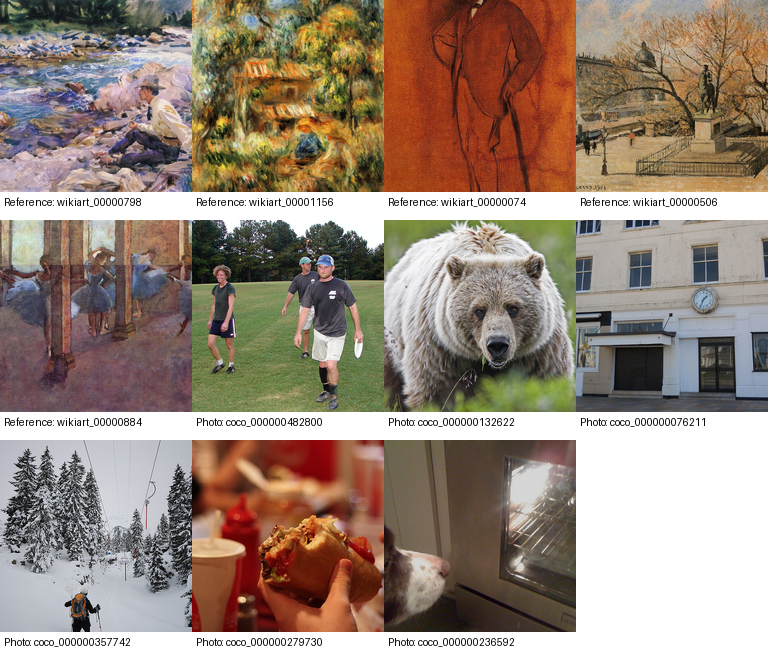

Картины: 75 Референсы: 5 Фото: 24
coco_000000482800 people — an image of three people playing Frisbee outside
coco_000000132622 animals — The large bear is looking in the direction of the camera.
coco_000000076211 urban — A clock mounted on the side of a building next to a street.
coco_000000357742 nature — A person on skis sliding up down a path.
coco_000000279730 objects — A person holding a sandwich next to a cup of coffee.
coco_000000236592 interiors — A dog eyeballing something cooking in the oven.


In [13]:
import json
from IPython.display import display, Image as DisplayImage

DATA_DIR = Path(subprocess.check_output([str(PYTHON), "-c", "from src.config import load_config,data_dir; print(data_dir(load_config()))"], cwd=REPO, text=True).strip())
display(DisplayImage(filename=str(DATA_DIR / "preview.png"), width=768))
art = [json.loads(line) for line in (DATA_DIR / "art_manifest.jsonl").read_text().splitlines()]
photos = [json.loads(line) for line in (DATA_DIR / "coco_manifest.jsonl").read_text().splitlines()]
print("Картины:", len(art), "Референсы:", sum(row["split"] == "reference" for row in art), "Фото:", len(photos))
for row in photos[:6]:
    print(row["id"], row["scene_group"], "—", row["prompt"])


## 8. Загрузка моделей и настоящий GPU smoke test

Скрипт загружает закреплённые SD 1.5, ControlNet и IP-Adapter, формирует фиксированный шум и генерирует две фотографии. Если этап завершился ошибкой, исправьте причину до полного запуска. Существующие успешные результаты проверяются и переиспользуются.


`torch_dtype` is deprecated! Use `dtype` instead!

Fetching 15 files: 100%|██████████| 15/15 [00:56<00:00,  3.74s/it]

Loading pipeline components...: 100%|██████████| 7/7 [01:18<00:00, 11.26s/it]

100%|██████████| 30/30 [00:27<00:00,  1.10it/s]
Generated coco_000000482800: 36.4s

100%|██████████| 30/30 [00:08<00:00,  3.46it/s]
Generated coco_000000132622: 12.3s
Run c66b0a9fe8ce4d583cfd: 2/24 images; /content/drive/MyDrive/diffusion_style_transfer/results/c66b0a9fe8ce4d583cfd


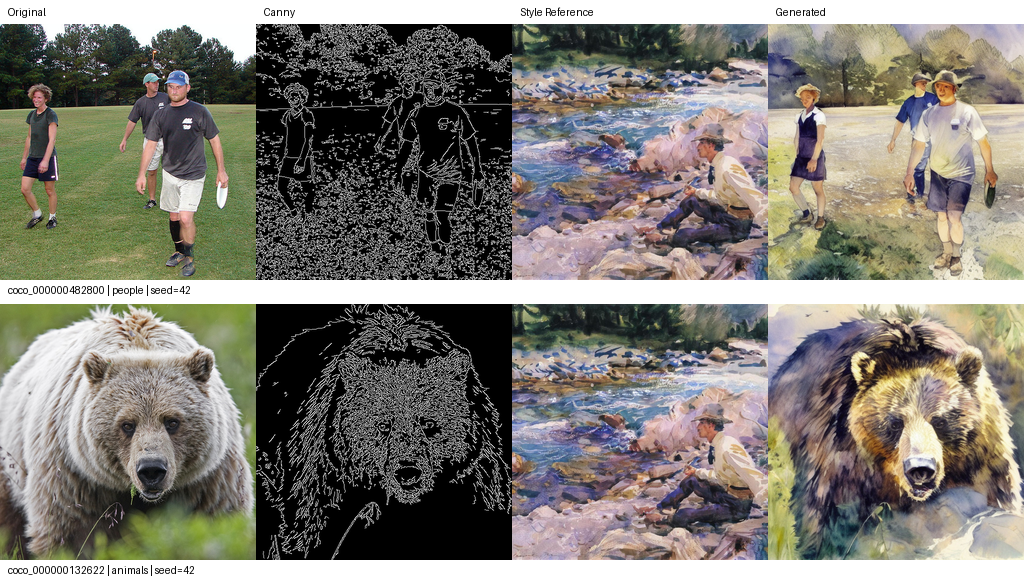

In [14]:
run_script("run_baseline.py", "--limit", "2")
RUN_DIR = HOME_DIR / "results" / json.loads((HOME_DIR / "results/current_run.json").read_text())["run_id"]
display(DisplayImage(filename=str(RUN_DIR / "figures/comparisons.png"), width=1000))


## 9. Основной baseline на 24 фото

Выполняются оставшиеся генерации с той же конфигурацией. После перезапуска Colab снова выполните ячейки сверху вниз: повторные скачивания данных и готовые генерации будут пропущены после проверки. Не запускайте несколько runtimes с записью в один каталог.


In [15]:
run_script("run_baseline.py")
RUN_DIR = HOME_DIR / "results" / json.loads((HOME_DIR / "results/current_run.json").read_text())["run_id"]
print(json.loads((RUN_DIR / "run.json").read_text())["completed_images"], "из 24")


`torch_dtype` is deprecated! Use `dtype` instead!

Loading pipeline components...: 100%|██████████| 7/7 [01:34<00:00, 13.46s/it]

100%|██████████| 30/30 [00:33<00:00,  1.13s/it]
Generated coco_000000076211: 39.2s

100%|██████████| 30/30 [00:07<00:00,  3.94it/s]
Generated coco_000000357742: 11.1s

100%|██████████| 30/30 [00:07<00:00,  3.95it/s]
Generated coco_000000279730: 11.2s

100%|██████████| 30/30 [00:07<00:00,  4.01it/s]
Generated coco_000000236592: 10.5s

100%|██████████| 30/30 [00:07<00:00,  3.85it/s]
Generated coco_000000255483: 10.9s

100%|██████████| 30/30 [00:07<00:00,  3.94it/s]
Generated coco_000000566042: 11.0s

100%|██████████| 30/30 [00:07<00:00,  3.85it/s]
Generated coco_000000044590: 10.9s

100%|██████████| 30/30 [00:07<00:00,  3.92it/s]
Generated coco_000000057597: 10.7s

100%|██████████| 30/30 [00:08<00:00,  3.72it/s]
Generated coco_000000367095: 11.4s

100%|██████████| 30/30 [00:08<00:00,  3.59it/s]
Generated coco_000000021167: 11.3s

100%|██████████| 30/30 [00:07<

RuntimeError: Command failed (1): /content/diffusion-style-env/bin/python /content/diffusion-style/scripts/run_baseline.py
 77%|███████▋  | 23/30 [00:06<00:01,  4.32it/s]
 80%|████████  | 24/30 [00:06<00:01,  4.39it/s]
 83%|████████▎ | 25/30 [00:06<00:01,  4.36it/s]
 87%|████████▋ | 26/30 [00:06<00:00,  4.46it/s]
 90%|█████████ | 27/30 [00:07<00:00,  4.53it/s]
 93%|█████████▎| 28/30 [00:07<00:00,  4.59it/s]
 97%|█████████▋| 29/30 [00:07<00:00,  4.61it/s]
100%|██████████| 30/30 [00:07<00:00,  4.67it/s]
100%|██████████| 30/30 [00:07<00:00,  3.83it/s]
Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.
Traceback (most recent call last):
  File "/content/diffusion-style/scripts/run_baseline.py", line 14, in <module>
    main()
    ~~~~^^
  File "/content/diffusion-style/scripts/run_baseline.py", line 10, in main
    run_baseline(load_config(args.config), limit=args.limit)
    ~~~~~~~~~~~~^^^^^^^^^

In [16]:
run_command(["git", "fetch", "origin", "main"], cwd=REPO)
run_command(["git", "checkout", "--detach", "FETCH_HEAD"], cwd=REPO)

run_script(
    "finalize_run.py",
    "--skip-photo", "coco_000000423971",
    "--reason", "safety_checker",
)

From https://github.com/Batyaoftheyear/diffusion-style
 * branch            main       -> FETCH_HEAD
   13220d2..c1507ad  main       -> origin/main
Previous HEAD position was 13220d2 fix: retry transient dataset failures and resume cached catalogues
HEAD is now at c1507ad fix: finalize existing baseline with explicit skipped samples
Existing run c66b0a9fe8ce4d583cfd: 23 generated, 1 explicitly skipped, 24 inputs. /content/drive/MyDrive/diffusion_style_transfer/results/c66b0a9fe8ce4d583cfd


## 10. Метрики и визуализация

Генерационные модели уже выгружены при завершении предыдущего процесса. DINOv2 запускается отдельно. Разброс в summary относится к фотографиям при одном seed, а не к устойчивости к шуму.


/content/diffusion-style-env/lib/python3.13/site-packages/huggingface_hub/file_download.py:801: UserWarning: Not enough free disk space to download the file. The expected file size is: 346.35 MB. The target location /content/drive/MyDrive/diffusion_style_transfer/.cache/huggingface/hub/models--facebook--dinov2-base/blobs only has 289.17 MB free disk space.
  warnings.warn(
Evaluated coco_000000482800
Evaluated coco_000000132622
Evaluated coco_000000076211
Evaluated coco_000000357742
Evaluated coco_000000279730
Evaluated coco_000000236592
Evaluated coco_000000255483
Evaluated coco_000000566042
Evaluated coco_000000044590
Evaluated coco_000000057597
Evaluated coco_000000367095
Evaluated coco_000000021167
Evaluated coco_000000361147
Evaluated coco_000000521231
Evaluated coco_000000017714
Evaluated coco_000000193181
Evaluated coco_000000006771
Evaluated coco_000000094336
Evaluated coco_000000283785
Evaluated coco_000000236730
Evaluated coco_000000503841
Evaluated coco_000000463542
Evaluate

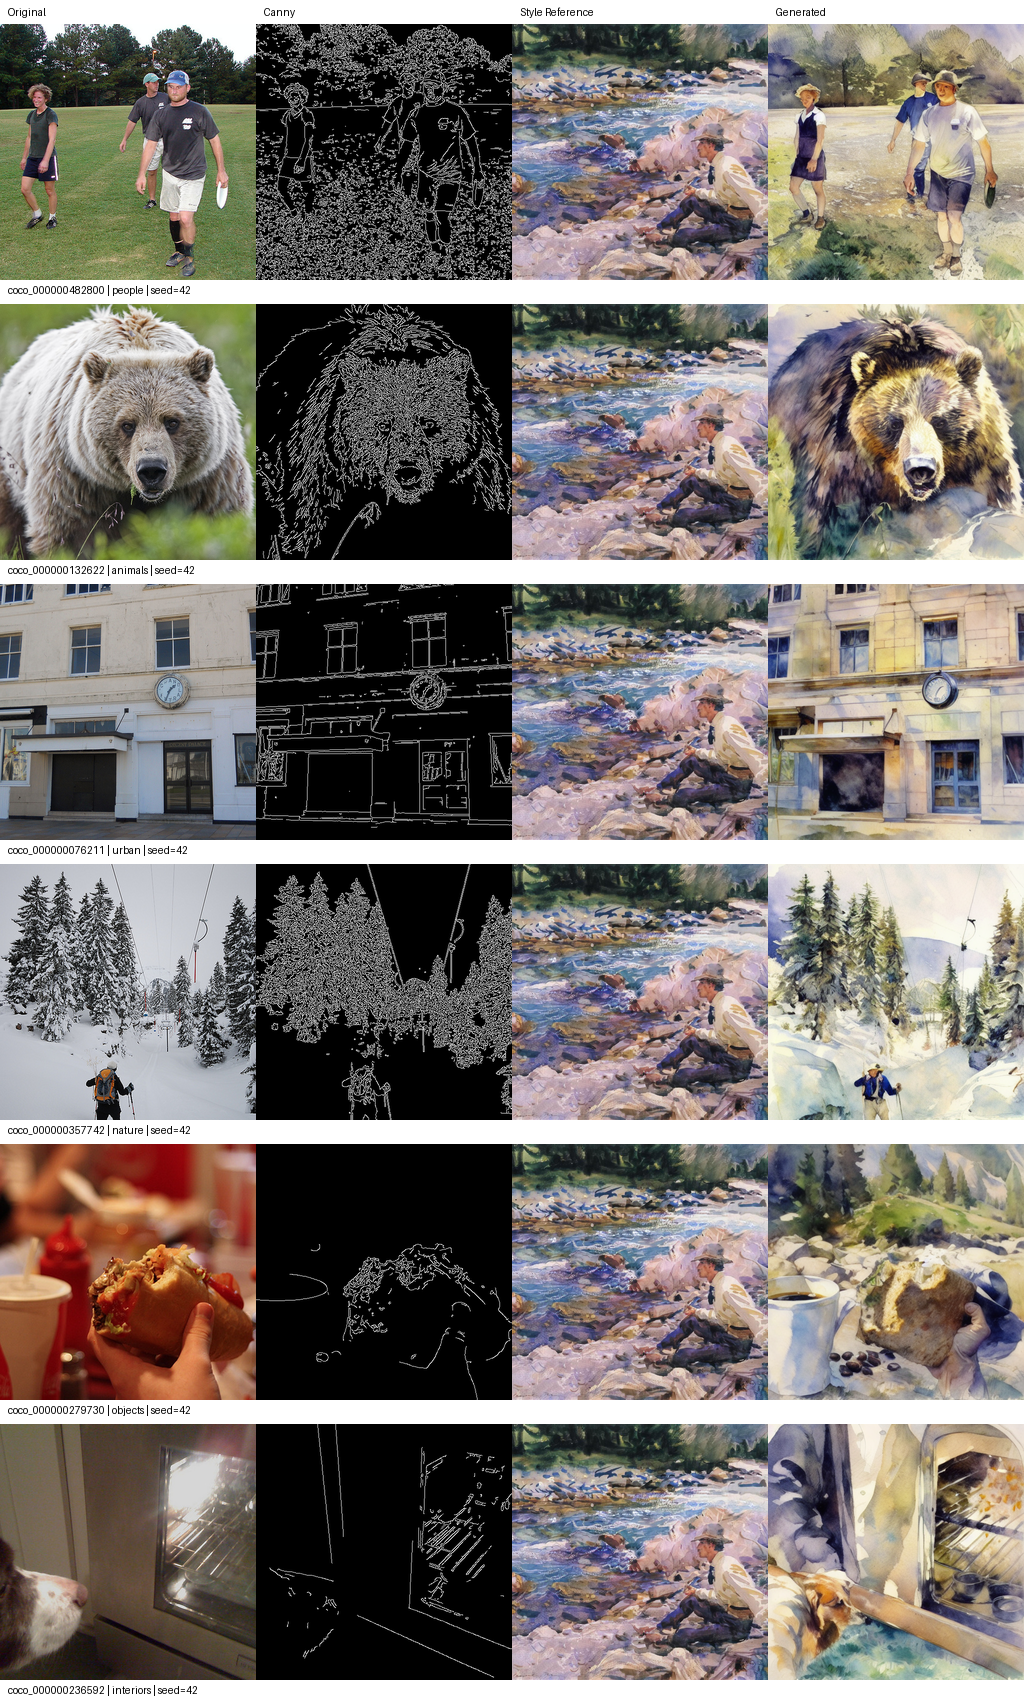

CSV: /content/drive/MyDrive/diffusion_style_transfer/results/c66b0a9fe8ce4d583cfd/metrics.csv


In [17]:
run_script("evaluate.py")
summary = json.loads((RUN_DIR / "summary.json").read_text())
for name, values in summary["metrics"].items():
    print(f"{name}: {values['mean']:.4f} ± {values['std']:.4f}; n={values['n']}")
display(DisplayImage(filename=str(RUN_DIR / "figures/comparisons.png"), width=1000))
print("CSV:", RUN_DIR / "metrics.csv")


## 11. Итоговый PDF

Обычный режим требует 24 действительных генерации и соответствующие метрики. Проверяются объём 4–6 страниц и извлечение кириллицы, затем создаются PNG страниц. Перед сдачей просмотрите их и сам PDF. Если GPU ещё не запускался, локально допускается только команда build_report.py --draft; такой документ не готов к сдаче.


FINAL: /content/drive/MyDrive/diffusion_style_transfer/reports/stage1_report.pdf; 6 pages


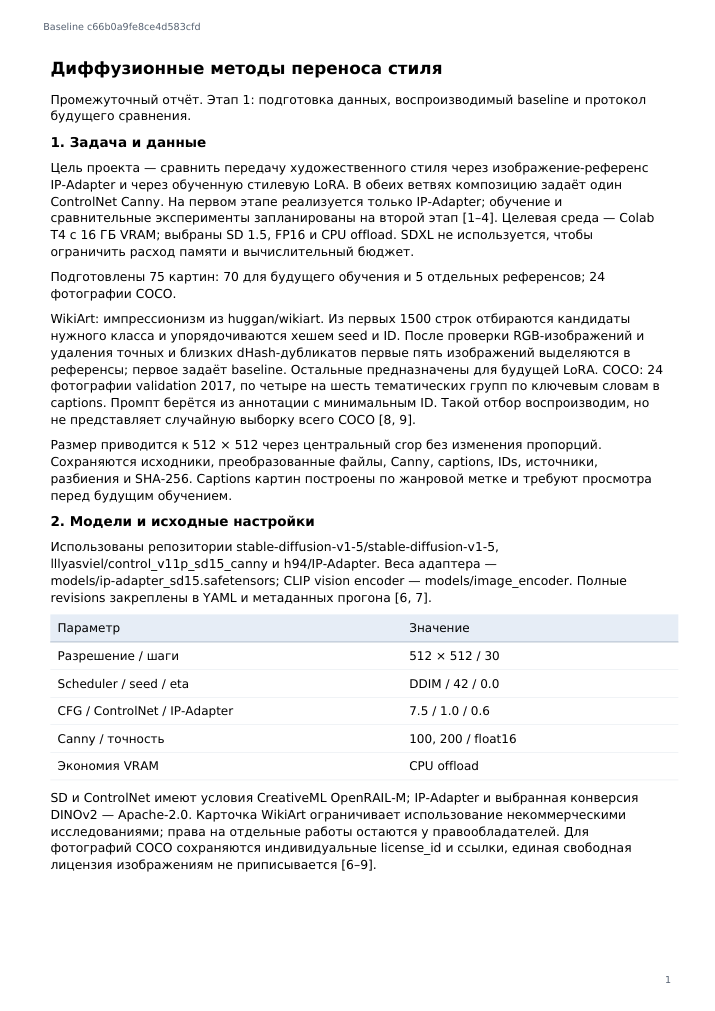

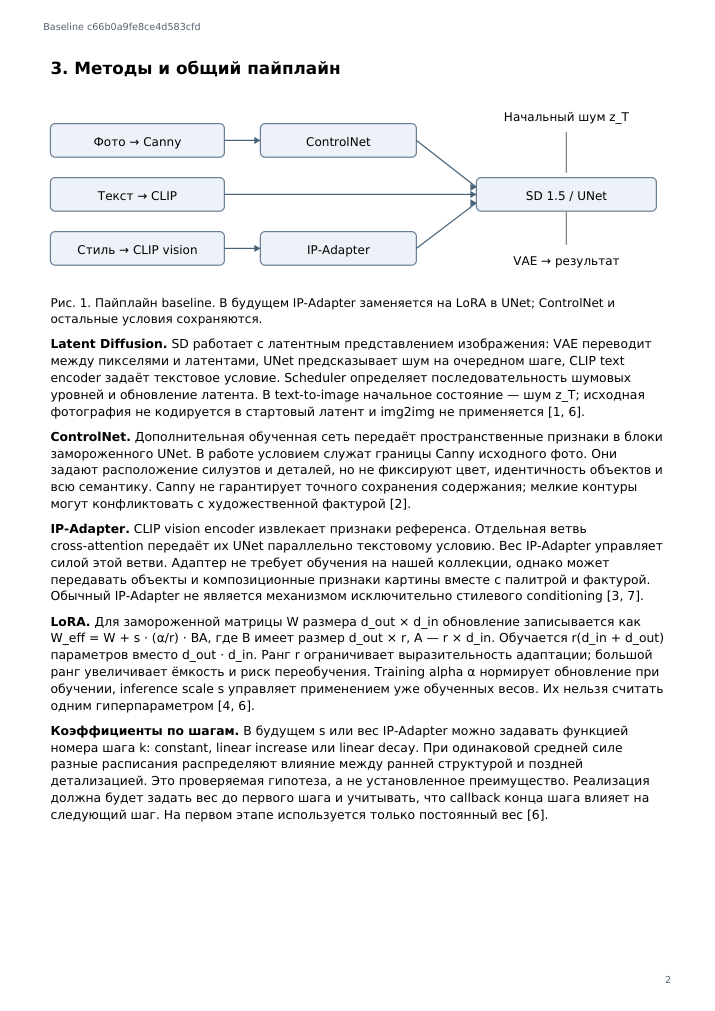

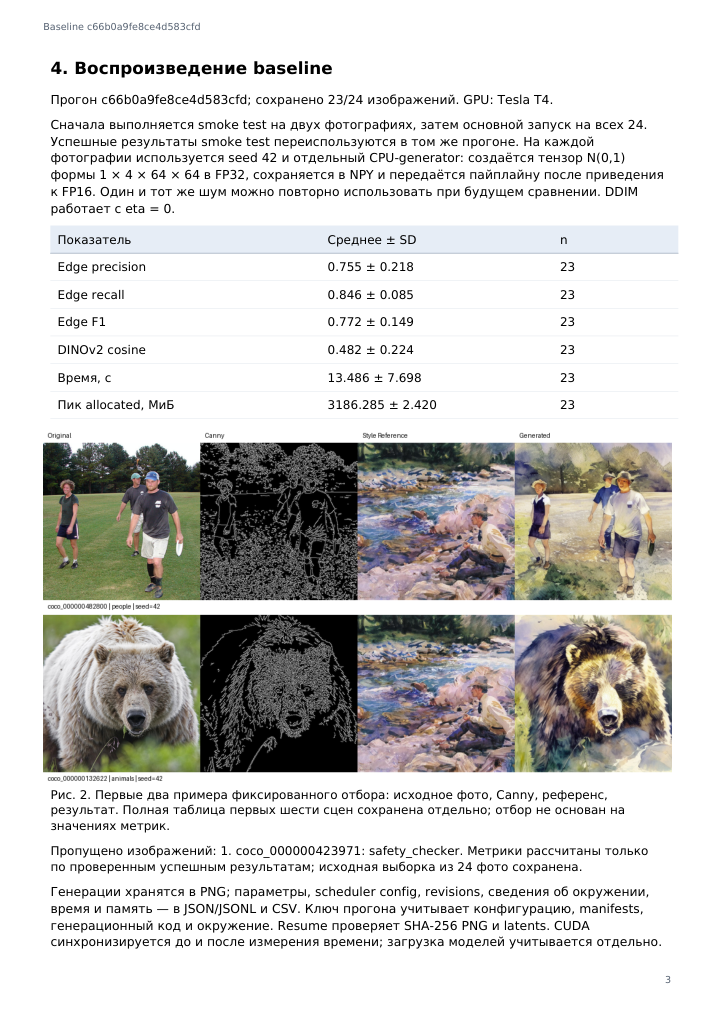

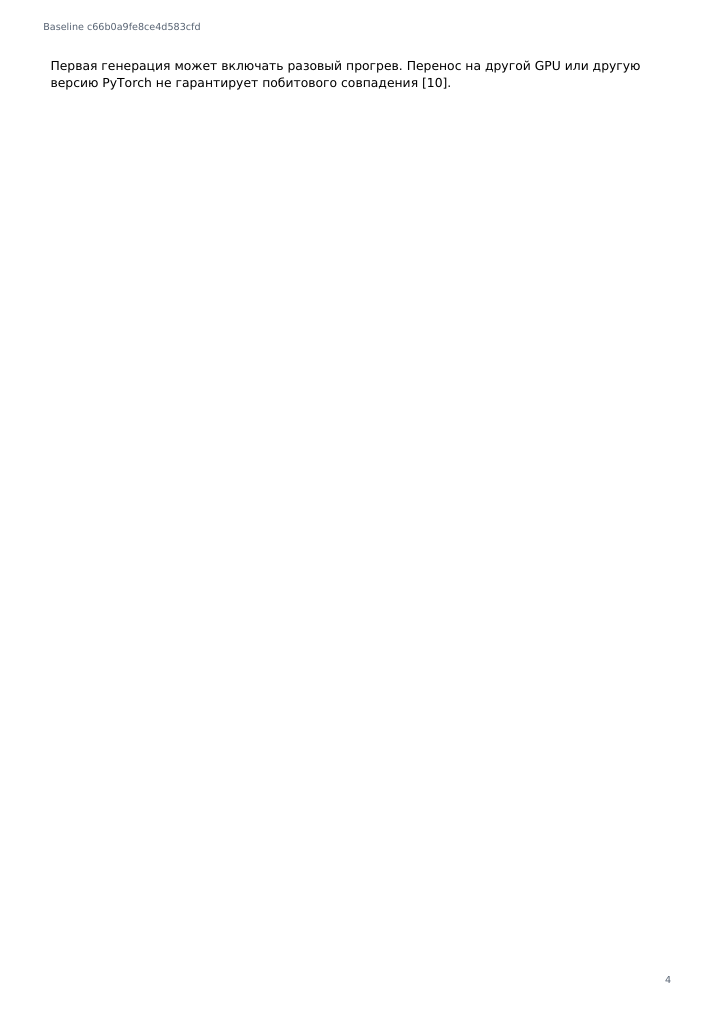

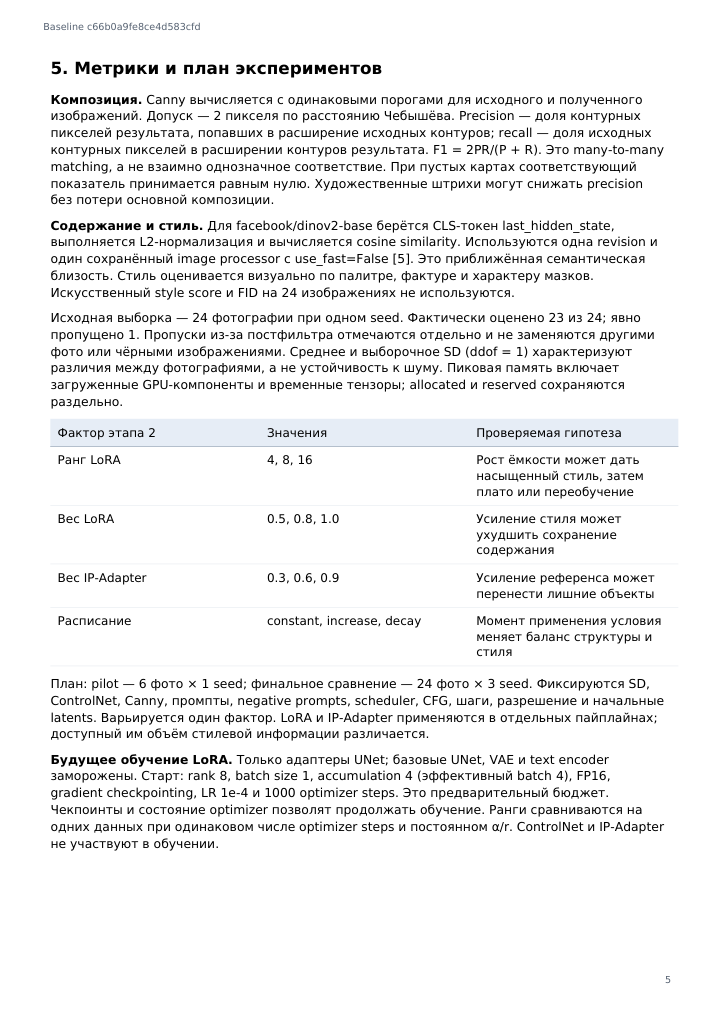

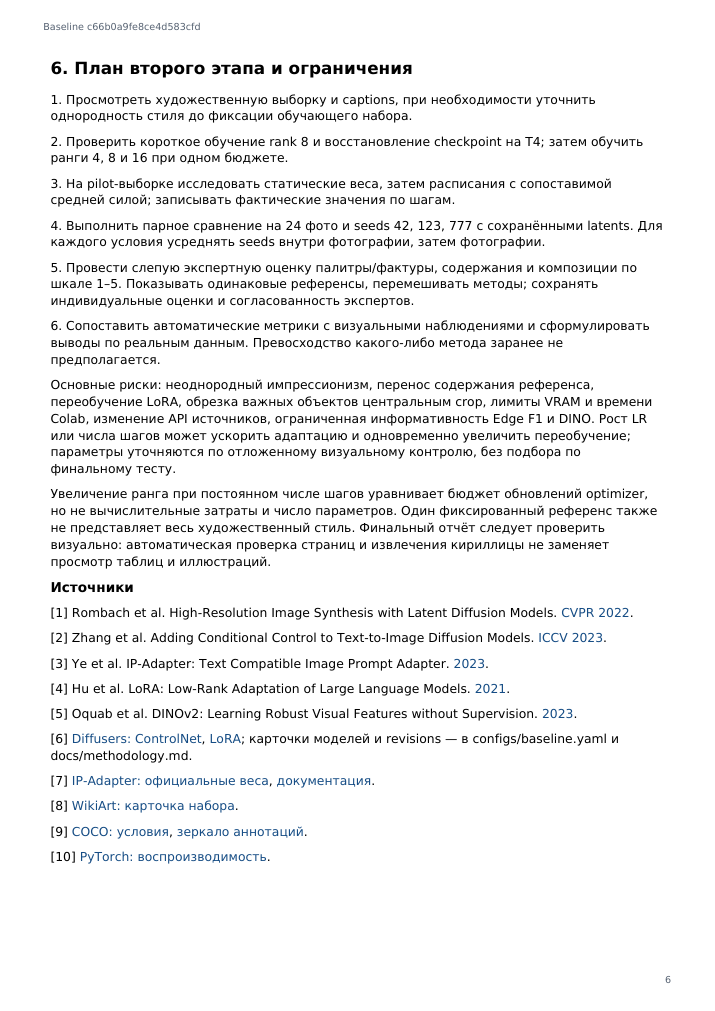

PDF для ЛМС: /content/drive/MyDrive/diffusion_style_transfer/reports/stage1_report.pdf
Метаданные PDF: {'draft': False, 'page_count': 6, 'run_id': 'c66b0a9fe8ce4d583cfd', 'evaluated_images': 23, 'source': 'docs/stage1_report.md'}


In [18]:
run_script("build_report.py", "--render")
PDF_PATH = HOME_DIR / "reports/stage1_report.pdf"
for preview in sorted((HOME_DIR / "reports/preview").glob("page_*.png")):
    display(DisplayImage(filename=str(preview), width=700))
print("PDF для ЛМС:", PDF_PATH)
print("Метаданные PDF:", json.loads(PDF_PATH.with_suffix(".json").read_text()))


## 12. Скачать отчёт

Результаты также остаются в MyDrive/diffusion_style_transfer. В ЛМС передаются окончательный PDF и ссылка на GitHub-репозиторий.


In [ ]:
from google.colab import files
files.download(str(PDF_PATH))
